<a href="https://colab.research.google.com/github/Shinyhunter95/Math-6010/blob/main/6010.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

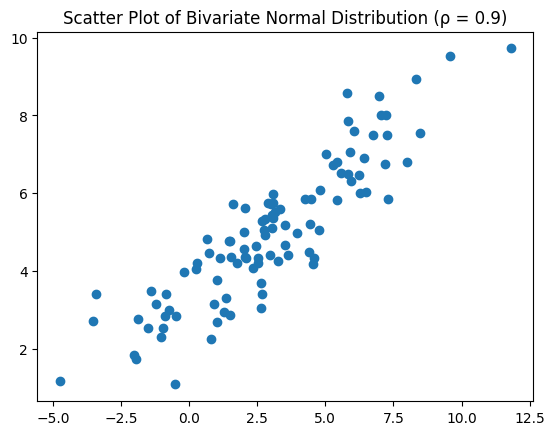

Epsilon [[ 6.97738434  8.50982794]
 [ 5.8331144   6.48166994]
 [ 3.52432552  4.66552781]
 [ 7.04043467  8.00777501]
 [ 2.62568041  3.05869183]
 [-4.74322674  1.17894832]
 [ 5.032643    7.01890254]
 [ 4.48902766  5.84508114]
 [ 1.01264216  2.69704079]
 [ 0.64919706  4.81057538]]
Mean [2.98643767 4.99415243]
Covariance [[9.31521584 4.97880816]
 [4.97880816 3.34376549]]
Eigenvalues of the Covariance Matrix EigResult(eigenvalues=array([13.43428318,  0.56571682]), eigenvectors=array([[ 0.85622789, -0.51659829],
       [ 0.51659829,  0.85622789]]))
Eigenvalues of the Covariance of X EigResult(eigenvalues=array([12.13492652,  0.5240548 ]), eigenvectors=array([[ 0.87014315, -0.49279905],
       [ 0.49279905,  0.87014315]]))


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

#Sigma^2_1 = 10 Sigma^2_2 = 4 Rho = .9
means = [3, 5]
c = (np.sqrt(10)*np.sqrt(4)*.9)
covariance = [[10, c],
              [c,  4]]

rng = np.random.default_rng(12345)
eps = rng.multivariate_normal(mean=means, cov=covariance, size=100)

plt.scatter(eps[:,0], eps[:,1])
plt.title("Scatter Plot of Bivariate Normal Distribution (\u03c1 = 0.9)")
plt.show()

print("Epsilon", eps[:10])

x_bar = np.mean(eps, axis=0)
print("Mean", x_bar)

x_cov = np.cov(eps.T)
print("Covariance", x_cov)

x_eig1 = np.linalg.eig(covariance)
print("Eigenvalues of the Covariance Matrix", x_eig1)

x_eig2 = np.linalg.eig(x_cov)
print("Eigenvalues of the Covariance of X", x_eig2)

/tmp/ipykernel_2500/2059677739.py:8: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(
[*********************100%***********************]  1 of 1 completed


                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.537
Model:                            OLS   Adj. R-squared:                  0.535
Method:                 Least Squares   F-statistic:                     289.5
Date:                Mon, 12 Oct 2026   Prob (F-statistic):           1.21e-43
Time:                        23:03:46   Log-Likelihood:                 512.88
No. Observations:                 252   AIC:                            -1022.
Df Residuals:                     250   BIC:                            -1015.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          3.5464      0.004    889.523      0.0

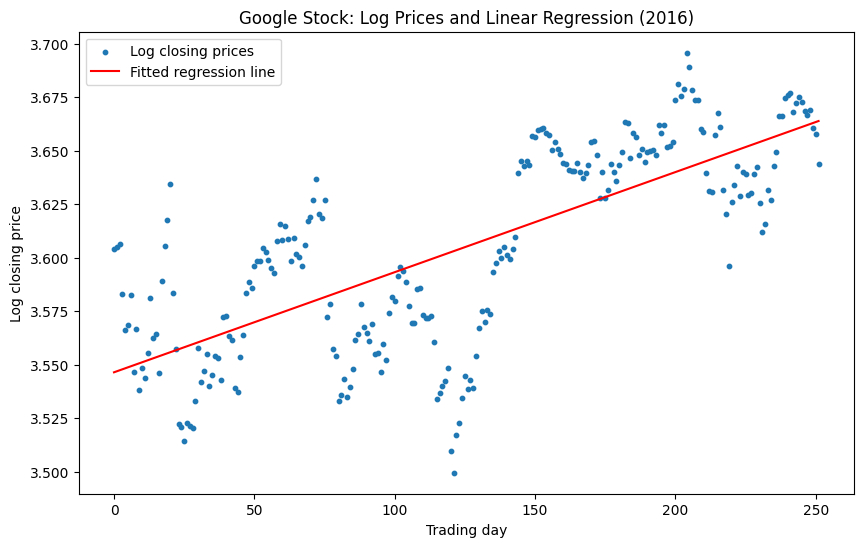

Intercept: 3.546430406755811
Estimated R: 0.00046761625364663984
R-squared: 0.5365809085731525


In [ ]:
import yfinance as yf
import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt

# Download Google's daily closing prices for 2016
data = yf.download(
    "GOOG",
    start="2016-01-01",
    end="2017-01-01"
)

# Extract closing prices
closing_prices = data["Close"]

# Handle possible multi-column output from yfinance
if isinstance(closing_prices, pd.DataFrame):
    closing_prices = closing_prices.iloc[:, 0]

# Take the logarithm
LC = np.log(closing_prices)

# Create the time variable (days since the first observation)
t = np.arange(len(LC))

# Set up the regression model
X = sm.add_constant(t)
model = sm.OLS(LC.to_numpy(), X).fit()

# Display the regression results
print(model.summary())

# Plot the log prices and fitted regression line
plt.figure(figsize=(10, 6))
plt.scatter(t, LC, s=10, label="Log closing prices")
plt.plot(t, model.predict(X), color="red", label="Fitted regression line")
plt.xlabel("Trading day")
plt.ylabel("Log closing price")
plt.title("Google Stock: Log Prices and Linear Regression (2016)")
plt.legend()
plt.show()

print("Intercept:", model.params[0])
print("Estimated R:", model.params[1])
print("R-squared:", model.rsquared)